# **Визуализация изображений в среде Collab**


## **Способ №1. Иcпользуя OpenCV и патч для Collab (Предпочтительный)**

In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

#### **Открываем изображение, используя локальный путь и сохраняем потоковый набор данных в переменную "image_1"**

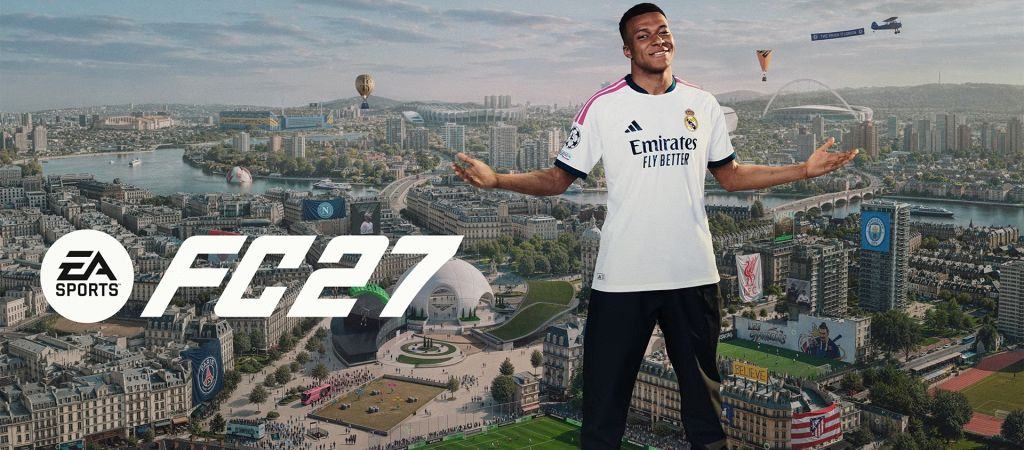

In [ ]:
# открываем изображение, используя локальный путь и сохраняем потоковый набор данных в переменную "image_1"
image_1 = cv2.imread("/content/assets_2026_07_1784281083_copy-of-ea_fc27_std_keyart_rgb_16x9_1920x1080.jpg")

cv2_imshow(image_1) # Выводим изображение, используя метод cv2_imshow()

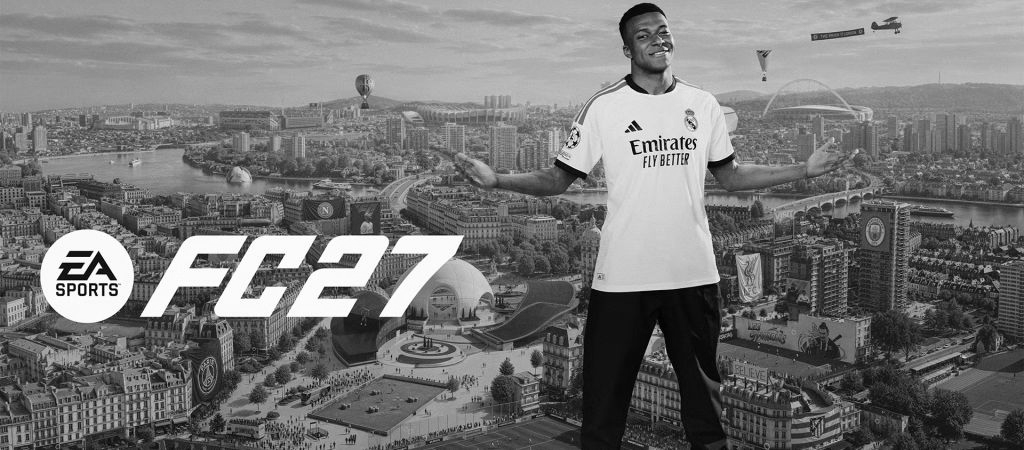

In [ ]:
# Преобразуем изображение в оттенки серого, используя корректную формулу
im_gray =  0.1140 * image_1[:,:, 0] + 0.5870 * image_1[:,:, 1] + 0.2989 * image_1[:,:, 2]

cv2_imshow(im_gray)

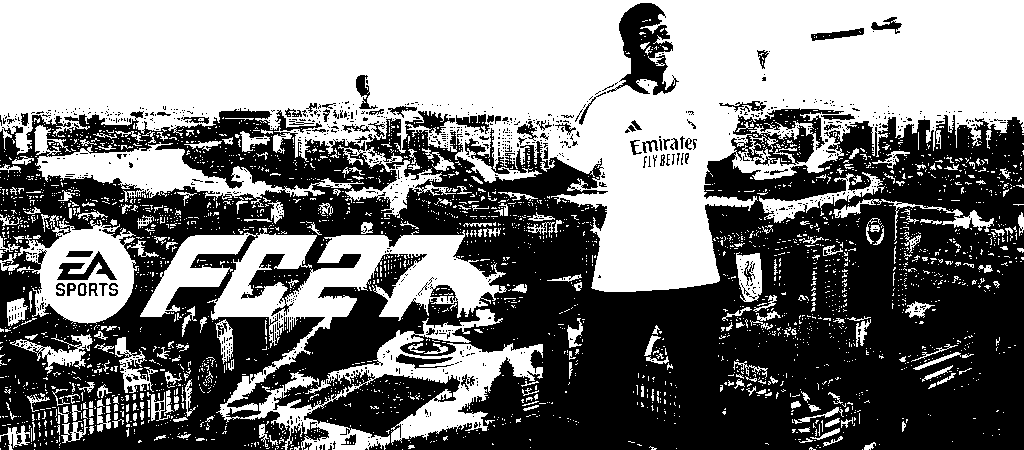

In [ ]:
# Преобразуем изображение в ч/б

im_black = im_gray.copy()

value = im_black.mean()

im_black[im_black > value] = 255
im_black[im_black <= value] = 0

cv2_imshow(im_black)

#### **Открываем изображение, используя его url-адрес в глобальной сети и сохраняем потоковый набор данных в переменную "image_2"**

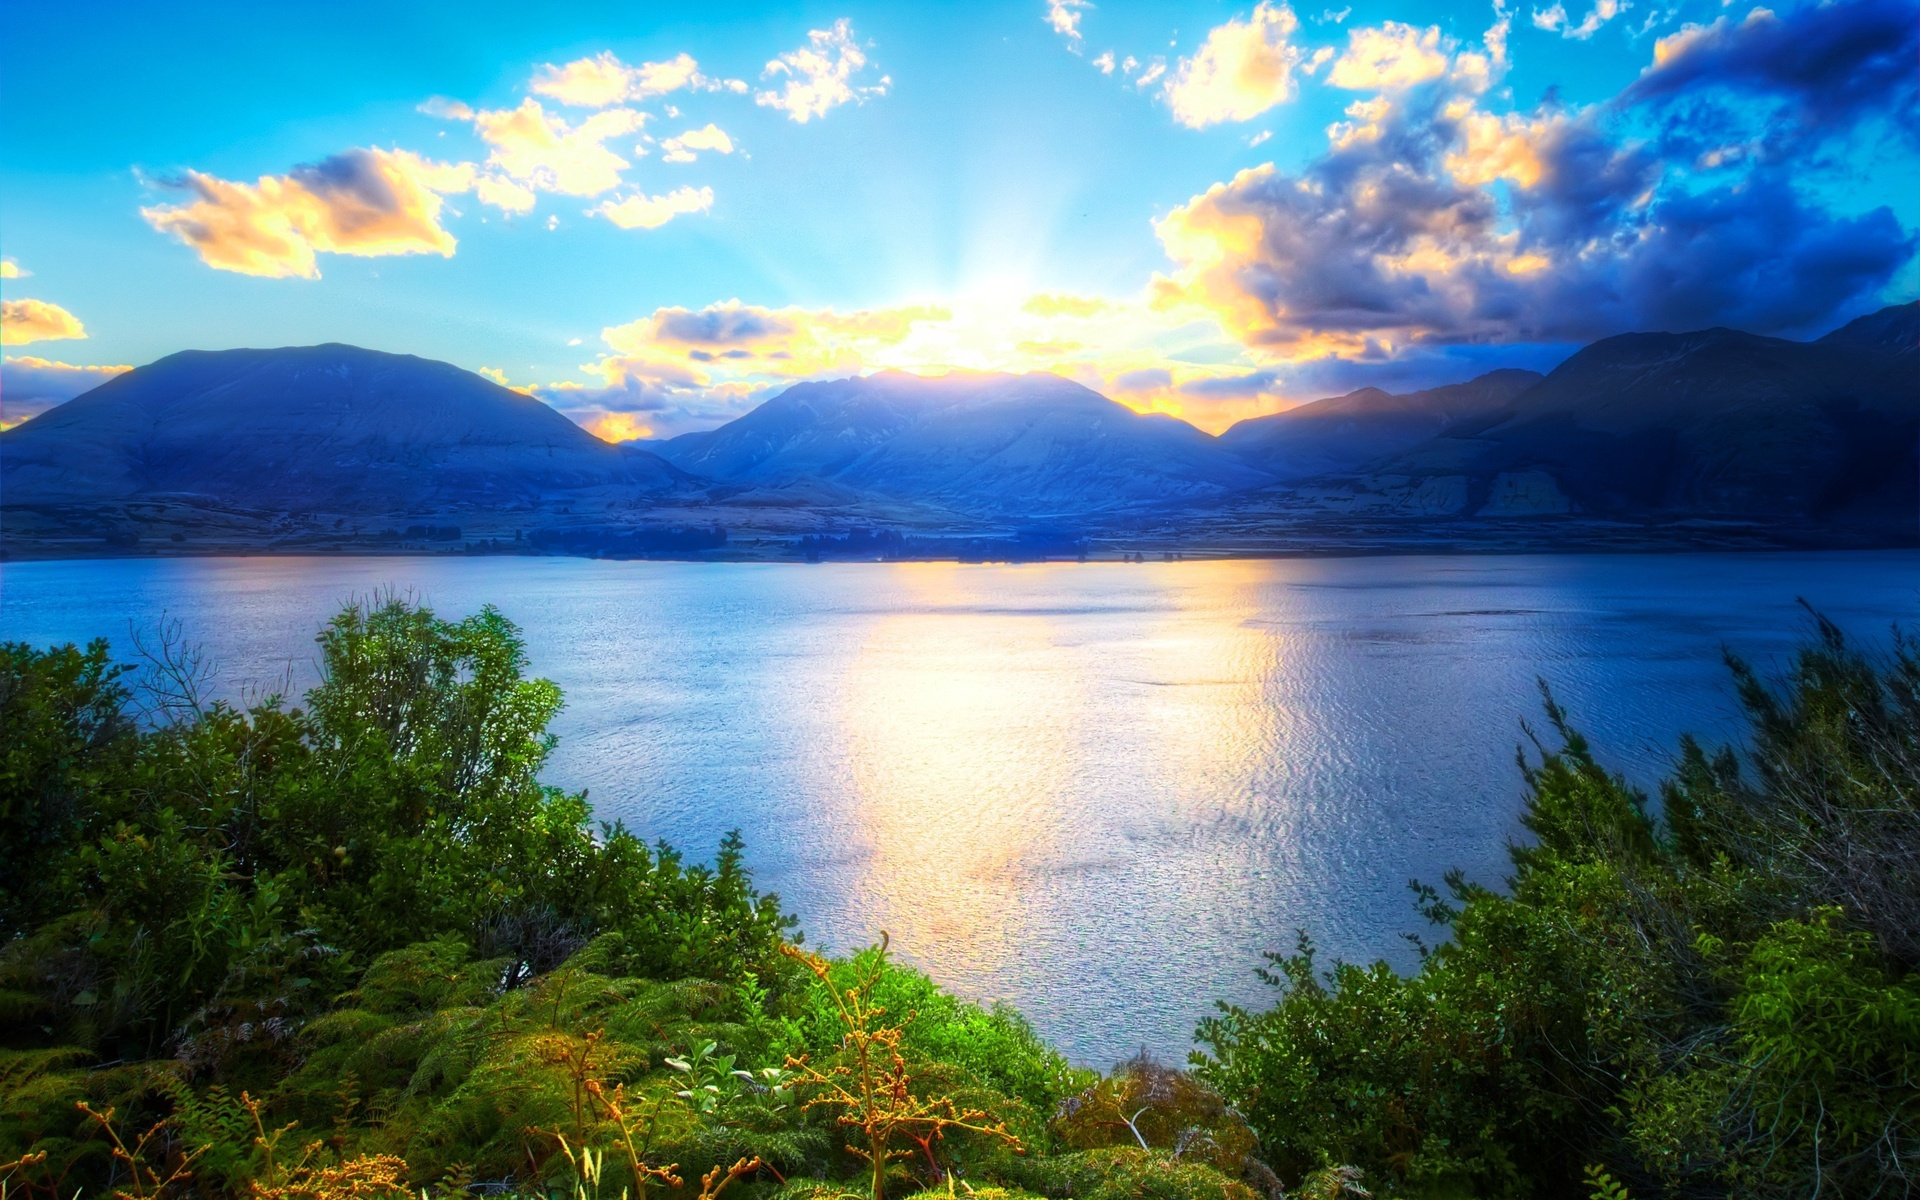

In [ ]:
from urllib.request import urlopen
req = urlopen('https://www.sunhome.ru/i/wallpapers/57/raiskoe-ozero.orig.jpg') # используя метод urlopen, получаем объект запроса по ссылке (изображение)
                                                                                      # и сохраняем его в виде потокового набора данных в переменную "req"

image_2 = np.asarray(bytearray(req.read()), dtype=np.uint8) # преобразуем потоковый набор данных в массив numpy
image_2 = cv2.imdecode(image_2, -1) # декодируем изображение в привычный для отображения формат

cv2_imshow(image_2) # Выводим изображение, используя метод cv2_imshow()

**Вывод нескольких изображений одновременно:**

*Вертикальный вывод*

In [ ]:
Verti = np.concatenate((image_2, image_2), axis=0) # Создаём новое изображение, используя конкатинацию массивов numpy

cv2_imshow(Verti) # Выводим изображение

*Горизонтальный вывод*

In [ ]:
Hori = np.concatenate((image_2, image_2), axis=1) # Создаём новое изображение, используя конкатинацию массивов numpy

cv2_imshow(Hori) # Выводим изображение

In [ ]:
cv2.imwrite('lala.jpg', Hori)

True

*Одновременный вывод нескольких разных изображений*

Для того чтобы вывести два изображения одновременно, необходимо привести их разрешение к единому значению

In [ ]:
# Получим параметры второго изображения
ver, hor, ch = image_2.shape # (1560, 2000, 3) - метод shape возвращает кортеж из 3х элементов (c_pxl по вертикали, c_pxl по горизонтали, кол-во каналов)

# Подгоним разрешение второго изображения, под параметры первого
image_1 = cv2.resize(image_1, (hor,ver), interpolation = cv2.INTER_AREA)


concatenate = np.concatenate((image_1, image_2), axis=1) # Создаём новое изображение, используя конкатинацию массивов numpy

cv2_imshow(concatenate) # Выводим изображение


# Способ №2. Иcпользуя модуль pyplot и OpenCV #

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

**Открываем изображение, используя локальный путь и сохраняем потоковый набор данных в переменную "image_1"**


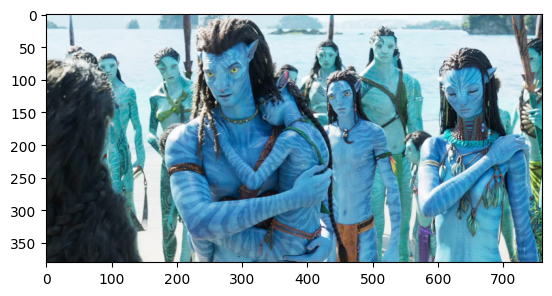

In [ ]:
image_1 = cv2.imread("/content/qUf_nw5vFw_3NbqEcJxJBA.png", -1)
image_1 = cv2.cvtColor(image_1, cv2.COLOR_BGR2RGB) # Преобразуем палитру цветов изображения в стандартную (RGB) из (BGR).

fig = plt.figure() # Figure - это контейнер самого верхнего уровня, та область на которой все визуализировано
plt.imshow(image_1) # Отображаем наше изображение

**Открываем изображение, используя его url-адрес в глобальной сети и сохраняем потоковый набор данных в переменную "image_2"**

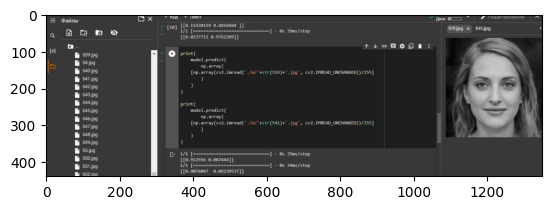

In [ ]:
from urllib.request import urlopen
req = urlopen('https://habrastorage.org/getpro/habr/upload_files/3ca/e1e/6b1/3cae1e6b1d032f1ea16ade54df628cf7.png') # используя метод urlopen, получаем объект запроса по ссылке (изображение)
                                                                                      # и сохраняем его в виде потокового набора данных в переменную "req"
image_2 = np.asarray(bytearray(req.read()), dtype=np.uint8) # преобразуем потоковый набор данных в массив numpy
image_2 = cv2.imdecode(image_2, -1) # декодируем изображение в привычный для отображения формат
image_2 = cv2.cvtColor(image_2, cv2.COLOR_BGR2RGB) # Преобразуем палитру цветов изображения в стандартную (RGB) из (BGR).
plt.imshow(image_2)  # Отображаем наше изображение

**Вывод нескольких изображений одновременно:**

*Вертикальный вывод:*

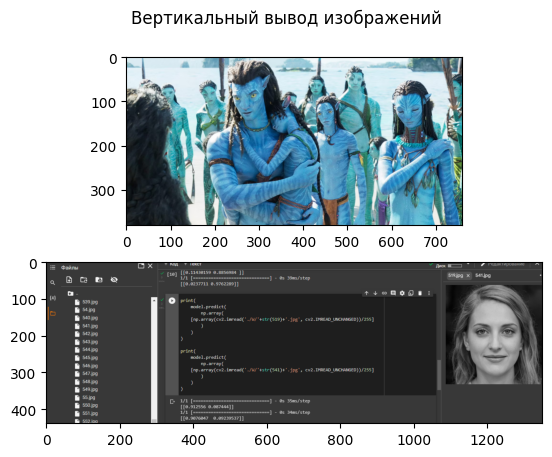

In [ ]:
#Создадим область для вывода изображений.
# fig - объект класса Figure. Глобальная область отображения
# axs - объект класса Axes. Область отображения для одного объекта (графика/изображения)

# Вы можете рассматривать объект Figure как похожий на ящик контейнер, содержащий один или несколько объектов Axes (настоящих графиков).
# Под объектами Axes, в порядке иерархии расположены меньшие объекты, такие как индивидуальные линии, отметки, легенды и текстовые боксы.

fig, axs = plt.subplots(nrows= 2 , ncols= 1 ) # указываем параметры области отображения (2 строки, 1 столбец)

# Добавим заголовок
fig.suptitle('Вертикальный вывод изображений')
axs[0].imshow(image_1) # Выводим первое изображение (верхнее)
axs[1].imshow(image_2) # Выводим первое изображение (нижнее)



*Горизонтальный вывод:*

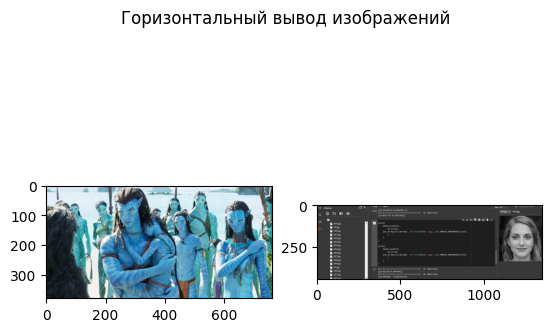

In [ ]:
fig, axs = plt.subplots(nrows= 1 , ncols= 2 ) # указываем параметры области отображения (1 строка, 2 столбца)

# Добавим заголовок
fig.suptitle('Горизонтальный вывод изображений')

axs[0].imshow(image_1) # Выводим первое изображение (верхнее)
axs[1].imshow(image_2) # Выводим первое изображение (нижнее)